# 🧩 Métodos de Ensamble — Notebook de estudio y práctica
### Minería de Datos y Aprendizaje Automático · Unidad: Ensembles (Bagging · Boosting · Stacking)

Este notebook sigue el orden de las diapositivas de la clase y le agrega:

* **Teoría ampliada** (fórmulas, intuición, hiperparámetros clave y errores típicos).
* **Ejemplos ejecutables** pensados para *ver* cómo funciona cada algoritmo.
* **Implementaciones "a mano"** de AdaBoost y Gradient Boosting que reproducen exactamente lo que hace `scikit-learn` (para entender, no para usar en producción).
* El **ejemplo numérico de Gradient Boosting de las diapositivas**, recalculado paso a paso.
* Una **plantilla completa para la Actividad 2** (dataset *glass*, 10 repeticiones, promedio e IC 95 %).
* Un **resumen final** y **preguntas de autoevaluación**.

> **Convención de nombres (igual que en clase):** `X` = atributos, `T` = target (clase real), `T_pred` = predicción.

---
## Índice
0. Configuración
1. ¿Qué es un ensamble y por qué funciona?
2. Bagging (bootstrapping, pasting, random subspace)
3. Random Forest
4. Boosting: idea general
5. AdaBoost (con implementación manual)
6. Gradient Boosting (con el ejemplo de las diapositivas)
7. XGBoost y LightGBM
8. Stacking (incluye stacking de múltiples capas, `cv` y `passthrough`)
9. Bonus: Voting (el pariente simple del stacking)
10. Comparación visual de fronteras de decisión
11. **Práctica guiada — Actividad 2 (glass)**
12. Resumen / machete y autoevaluación

## 0. Configuración

En **Google Colab** casi todo viene instalado. Si falta `xgboost` o `lightgbm`, descomentá la línea de `pip`.

In [1]:
# !pip install -q xgboost lightgbm

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import stats

from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

try:
    from xgboost import XGBClassifier
    HAY_XGB = True
except ImportError:
    HAY_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAY_LGBM = True
except ImportError:
    HAY_LGBM = False

import sklearn
print("scikit-learn:", sklearn.__version__, "| XGBoost:", HAY_XGB, "| LightGBM:", HAY_LGBM)

plt.rcParams["figure.dpi"] = 100
SEED = 42

scikit-learn: 1.6.1 | XGBoost: True | LightGBM: True


### Funciones auxiliares
Las usamos a lo largo de todo el notebook. No hace falta entenderlas en detalle ahora.

In [2]:
CMAP_FONDO = ListedColormap(["#FFD6D6", "#D6E4FF"])
CMAP_PUNTOS = ListedColormap(["#D62728", "#1F77B4"])

def graficar_frontera(modelo, X, T, ax=None, titulo=""):
    # Dibuja la frontera de decision de un clasificador entrenado sobre datos 2D.
    if ax is None:
        ax = plt.gca()
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=CMAP_FONDO, alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=T, cmap=CMAP_PUNTOS, s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(titulo, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

def intervalo_confianza_95(valores):
    # Media e IC 95% con t de Student (adecuado para pocas repeticiones, ej. n=10).
    valores = np.asarray(valores, dtype=float)
    n = len(valores)
    media = valores.mean()
    s = valores.std(ddof=1)            # desvio muestral
    t_crit = stats.t.ppf(0.975, df=n - 1)
    margen = t_crit * s / np.sqrt(n)
    return media, media - margen, media + margen

# Datos 2D de juguete para las visualizaciones
X_moons, T_moons = make_moons(n_samples=400, noise=0.30, random_state=SEED)
Xm_train, Xm_test, Tm_train, Tm_test = train_test_split(X_moons, T_moons, test_size=0.3, random_state=SEED)
print("Funciones listas. Dataset 'moons':", X_moons.shape)

Funciones listas. Dataset 'moons': (400, 2)


---
## 1. ¿Qué es un ensamble y por qué funciona?

Un **ensamble** es un conjunto de modelos individuales (**estimadores base**) cuyas predicciones se **combinan** para producir una predicción final. Según las diapositivas:

* **Reducen el error** de predicción.
* **Mantienen una buena generalización.**

### La intuición: "la sabiduría de las multitudes"
Si tenemos muchos clasificadores que **aciertan un poco más que el azar** y que **se equivocan en cosas distintas** (errores poco correlacionados), al votar los errores se compensan.

Supongamos $n$ clasificadores **independientes**, cada uno con probabilidad de acierto $p$. La votación por mayoría acierta cuando más de la mitad acierta:

$$P(\text{ensamble acierta}) = \sum_{k > n/2}^{n} \binom{n}{k} p^k (1-p)^{n-k}$$

⚠️ **La clave es la diversidad.** Si todos los modelos son iguales (cometen los mismos errores), votar no sirve de nada. Por eso cada familia de ensambles busca generar diversidad de una forma distinta:

| Familia | ¿Cómo genera diversidad? | ¿Qué reduce principalmente? | Entrenamiento |
|---|---|---|---|
| **Bagging** / Random Forest | Distintas muestras (y atributos) del dataset | **Varianza** (sobreajuste) | En **paralelo** |
| **Boosting** (AdaBoost, GB, XGBoost) | Cada modelo se enfoca en los errores del anterior | **Sesgo** (subajuste) | **Secuencial** |
| **Stacking** | Modelos de **naturaleza distinta** + un meta-modelo | Ambos (aprende a combinar) | Base en paralelo + meta-modelo |

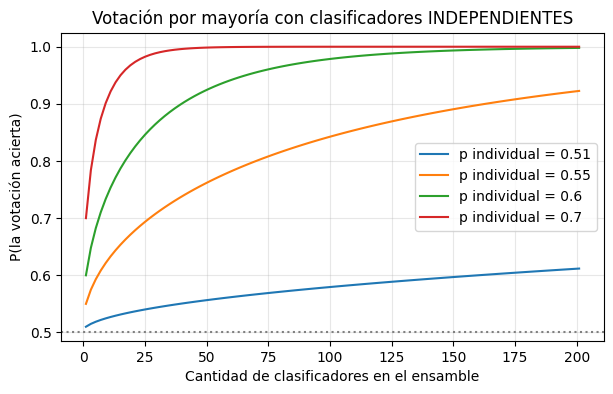

1 clasificador con p=0.60 acierta el 60% de las veces.
101 clasificadores independientes con p=0.60 -> la mayoría acierta el 97.9%


In [ ]:
from scipy.stats import binom

def prob_mayoria(n, p):
    # P(mas de la mitad acierta) con n votantes independientes
    return 1 - binom.cdf(n // 2, n, p)

ns = np.arange(1, 202, 2)   # cantidad impar de clasificadores (evita empates)
plt.figure(figsize=(7, 4))
for p in [0.51, 0.55, 0.60, 0.70]:
    plt.plot(ns, [prob_mayoria(n, p) for n in ns], label=f"p individual = {p}")
plt.axhline(0.5, color="gray", ls=":")
plt.xlabel("Cantidad de clasificadores en el ensamble")
plt.ylabel("P(la votación acierta)")
plt.title("Votación por mayoría con clasificadores INDEPENDIENTES")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"1 clasificador con p=0.60 acierta el 60% de las veces.")
print(f"101 clasificadores independientes con p=0.60 -> la mayoría acierta el {prob_mayoria(101, 0.6):.1%}")

> **Ojo con la hipótesis de independencia:** en la práctica los modelos se entrenan con los mismos datos, así que sus errores están correlacionados y la mejora es **mucho menor** que la del gráfico. Por eso Random Forest agrega aleatoriedad extra (sorteo de atributos) para **descorrelacionar** los árboles.

### Sesgo y varianza en una frase
* **Varianza alta** = el modelo cambia mucho si cambian un poco los datos (ej. un árbol muy profundo). → *Bagging promedia y la reduce.*
* **Sesgo alto** = el modelo es demasiado simple y no captura el patrón (ej. un árbol de 1 nivel, "stump"). → *Boosting suma modelos simples y lo reduce.*

---
## 2. Bagging (*Bootstrap AGGregatING*)

Se entrenan **N estimadores del mismo tipo**, cada uno con una **versión distinta del dataset**, y la clase final es **la más votada**.

Formas de armar cada "versión" del dataset (diapositiva *Bagging*):

| Técnica | Qué se sortea | Con reemplazo | En `BaggingClassifier` |
|---|---|---|---|
| **Bootstrapping** | Filas | **Sí** | `bootstrap=True` (default) |
| **Pasting** | Filas | **No** | `bootstrap=False, max_samples=0.7` |
| **Random subspace** | Columnas (atributos) | — | `max_features=0.5, bootstrap=False, max_samples=1.0` |
| **Random patches** | Filas **y** columnas | — | `max_samples<1` y `max_features<1` |

### ¿Cuántas filas distintas tiene una muestra bootstrap?
Si sorteamos $n$ filas **con reemplazo** de un dataset de $n$ filas, la probabilidad de que una fila **no** salga nunca es $(1-\tfrac{1}{n})^n \to e^{-1} \approx 0.368$.
Es decir, cada árbol ve **≈ 63,2 %** de las filas distintas; el **≈ 36,8 %** restante son las muestras **OOB** (*out-of-bag*), que sirven como un "test gratis".

In [ ]:
rng = np.random.default_rng(SEED)
n = 1000
indices = rng.integers(0, n, size=n)          # muestra bootstrap: n sorteos con reemplazo
unicos = len(np.unique(indices))
print(f"Filas distintas en la muestra bootstrap: {unicos} de {n} ({unicos/n:.1%})")
print(f"Filas OOB (no elegidas): {n-unicos} ({(n-unicos)/n:.1%})  -> teórico 36.8%")

# Ejemplo chiquito para "ver" el bootstrap
ids = np.arange(10)
print("\nDataset original :", ids)
for i in range(3):
    muestra = rng.choice(ids, size=10, replace=True)
    oob = np.setdiff1d(ids, muestra)
    print(f"Bootstrap #{i+1}     : {np.sort(muestra)}   OOB: {oob}")
print("Pasting (sin reemplazo, 70%):", np.sort(rng.choice(ids, size=7, replace=False)))

Filas distintas en la muestra bootstrap: 637 de 1000 (63.7%)
Filas OOB (no elegidas): 363 (36.3%)  -> teórico 36.8%

Dataset original : [0 1 2 3 4 5 6 7 8 9]
Bootstrap #1     : [1 5 5 5 7 7 8 8 8 9]   OOB: [0 2 3 4 6]
Bootstrap #2     : [0 1 2 2 3 3 4 5 7 8]   OOB: [6 9]
Bootstrap #3     : [0 0 0 0 2 3 5 8 8 8]   OOB: [1 4 6 7 9]
Pasting (sin reemplazo, 70%): [0 1 2 4 6 7 9]


### Un árbol solo vs. Bagging de árboles
Un árbol sin límite de profundidad **memoriza** el ruido (frontera muy irregular = alta varianza). Al promediar 200 árboles entrenados con muestras bootstrap, la frontera se suaviza.

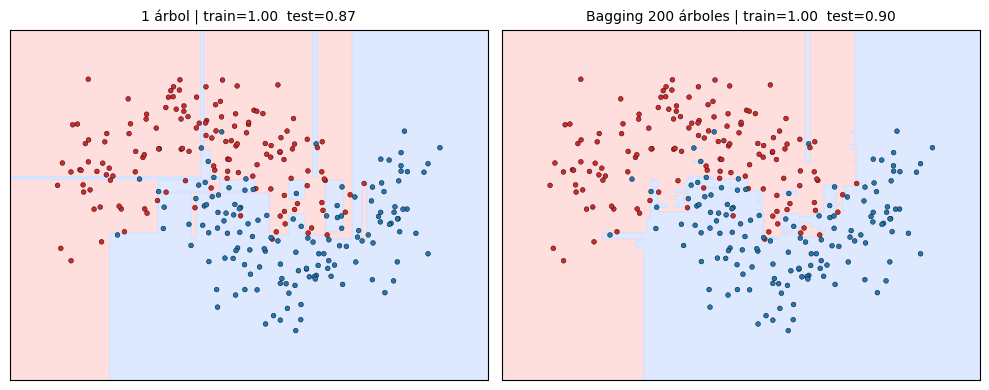

Accuracy OOB del bagging (estimación sin usar test): 0.850


In [ ]:
arbol = DecisionTreeClassifier(random_state=SEED).fit(Xm_train, Tm_train)

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(),   # estimador base
    n_estimators=200,                      # cantidad de modelos
    bootstrap=True,                        # True = bootstrapping (con reemplazo)
    oob_score=True,                        # evalúa con las muestras out-of-bag
    n_jobs=-1, random_state=SEED
).fit(Xm_train, Tm_train)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
graficar_frontera(arbol, Xm_train, Tm_train, axs[0],
                  f"1 árbol | train={arbol.score(Xm_train, Tm_train):.2f}  test={arbol.score(Xm_test, Tm_test):.2f}")
graficar_frontera(bag, Xm_train, Tm_train, axs[1],
                  f"Bagging 200 árboles | train={bag.score(Xm_train, Tm_train):.2f}  test={bag.score(Xm_test, Tm_test):.2f}")
plt.tight_layout(); plt.show()
print(f"Accuracy OOB del bagging (estimación sin usar test): {bag.oob_score_:.3f}")

### Las variantes en código

In [ ]:
variantes = {
    "Bootstrapping": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                       bootstrap=True, random_state=SEED),
    "Pasting (70% filas)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                             bootstrap=False, max_samples=0.7, random_state=SEED),
    "Random subspace (50% cols)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                                    bootstrap=False, max_samples=1.0,
                                                    max_features=0.5, random_state=SEED),
    "Random patches": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100,
                                        max_samples=0.7, max_features=0.5, random_state=SEED),
}

# Usamos un dataset real con muchas columnas para que el sorteo de atributos tenga sentido
X_bc, T_bc = load_breast_cancer(return_X_y=True, as_frame=True)
Xbc_train, Xbc_test, Tbc_train, Tbc_test = train_test_split(
    X_bc, T_bc, test_size=0.25, stratify=T_bc, random_state=SEED)

for nombre, modelo in variantes.items():
    modelo.fit(Xbc_train, Tbc_train)
    print(f"{nombre:28s} accuracy test = {modelo.score(Xbc_test, Tbc_test):.3f}")

Bootstrapping                accuracy test = 0.951


Pasting (70% filas)          accuracy test = 0.951


Random subspace (50% cols)   accuracy test = 0.951


Random patches               accuracy test = 0.958


### Votación dura vs. blanda
* **Dura (hard voting):** cada modelo emite una clase; gana la más votada.
* **Blanda (soft voting):** se **promedian las probabilidades** y gana la de mayor promedio.

`BaggingClassifier` y `RandomForestClassifier` de scikit-learn usan **votación blanda** (promedian `predict_proba`). Cuando los árboles crecen hasta tener hojas puras, cada árbol da probabilidad 0 o 1, así que el promedio **coincide** con la proporción de votos que muestran las diapositivas.

---
## 3. Random Forest

Es un **bagging de árboles de decisión** con un ingrediente extra:

1. Cada árbol se entrena con una **muestra bootstrap** de las filas (igual que bagging).
2. **En cada nodo**, el árbol sólo puede elegir el mejor corte entre un **subconjunto aleatorio de atributos** (`max_features`). ¡Se sortea en **cada división**, no una sola vez por árbol!
3. La predicción final se hace por **votación**.

Ese sorteo de atributos **descorrelaciona** los árboles: si hay un atributo muy dominante, no todos los árboles lo van a usar arriba de todo.

En el ejemplo de la diapositiva (perro/gato), 5 de 6 árboles votan *Gato* → predicción **Gato (5/6 ≈ 0,83)**.

### Hiperparámetros que más importan
| Parámetro | Qué controla | Valores típicos |
|---|---|---|
| `n_estimators` | Cantidad de árboles. Más árboles **no sobreajusta**, sólo cuesta más tiempo. | 100–1000 |
| `max_features` | Atributos candidatos por nodo. Menos = árboles más distintos. | `"sqrt"` (default en clasificación), `"log2"`, 0.3–0.5 |
| `max_depth`, `min_samples_leaf` | Complejidad de cada árbol | `None` / 1–5 |
| `bootstrap`, `oob_score` | Muestreo y evaluación OOB | `True` |
| `class_weight` | Compensar clases desbalanceadas | `"balanced"` |
| `n_jobs=-1` | Usa todos los núcleos (los árboles son independientes) | — |

In [ ]:
rf = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=SEED)
model = rf.fit(Xbc_train, Tbc_train)

T_pred = model.predict(Xbc_test)
print("Accuracy test:", round(accuracy_score(Tbc_test, T_pred), 3), "| Accuracy OOB:", round(model.oob_score_, 3))

# predict_proba = proporción (promedio) de votos de los 1000 árboles
proba = model.predict_proba(Xbc_test)
print("\nPrimeras 5 filas de predict_proba  [P(clase 0), P(clase 1)]:")
print(np.round(proba[:5], 3))

# Verificación: es exactamente el promedio de las probabilidades de cada árbol
manual = np.mean([arbol.predict_proba(Xbc_test.values) for arbol in model.estimators_], axis=0)
print("\n¿predict_proba == promedio de los árboles?", np.allclose(manual, proba))

Accuracy test: 0.958 | Accuracy OOB: 0.962

Primeras 5 filas de predict_proba  [P(clase 0), P(clase 1)]:
[[0.015 0.985]
 [1.    0.   ]
 [0.339 0.661]
 [0.099 0.901]
 [0.266 0.734]]

¿predict_proba == promedio de los árboles? True


### Mirar un árbol del bosque (`rf.estimators_[i]`)

Profundidad del árbol 0: 7 | hojas: 20


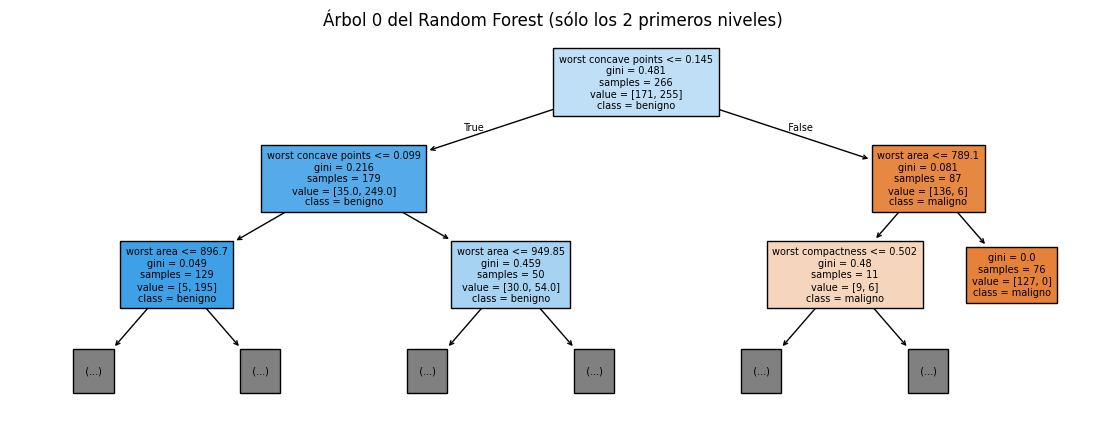

In [ ]:
e = rf.estimators_[0]    # primer árbol (zero-based)
print("Profundidad del árbol 0:", e.get_depth(), "| hojas:", e.get_n_leaves())

plt.figure(figsize=(14, 5))
plot_tree(e, max_depth=2, feature_names=X_bc.columns, class_names=["maligno", "benigno"],
          filled=True, fontsize=7)
plt.title("Árbol 0 del Random Forest (sólo los 2 primeros niveles)")
plt.show()

### Importancia de atributos
Random Forest mide cuánto reduce la impureza cada atributo (promediado en todos los árboles). Es útil para interpretar el modelo.

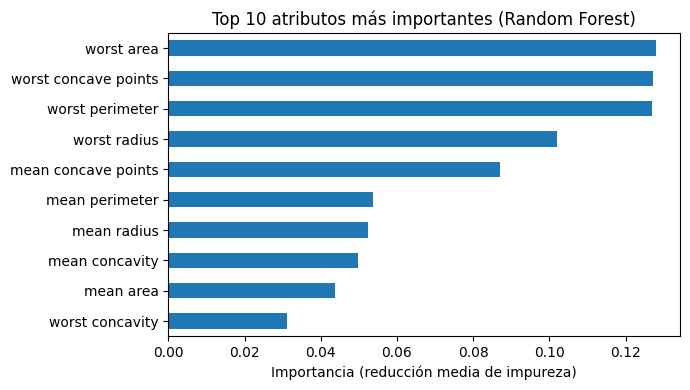

In [ ]:
importancias = pd.Series(rf.feature_importances_, index=X_bc.columns).sort_values()
importancias.tail(10).plot.barh(figsize=(7, 4), title="Top 10 atributos más importantes (Random Forest)")
plt.xlabel("Importancia (reducción media de impureza)"); plt.tight_layout(); plt.show()

### ¿Cuántos árboles hacen falta?
Usamos el error **OOB** a medida que agregamos árboles (`warm_start=True` reutiliza los árboles ya entrenados).

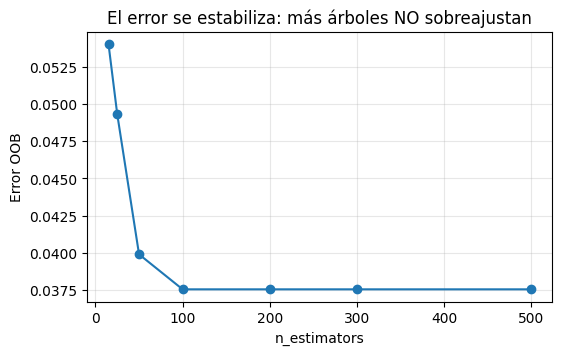

In [ ]:
rf_ws = RandomForestClassifier(warm_start=True, oob_score=True, n_jobs=-1, random_state=SEED)
cantidades = [15, 25, 50, 100, 200, 300, 500]
errores_oob = []
for k in cantidades:
    rf_ws.set_params(n_estimators=k)
    rf_ws.fit(Xbc_train, Tbc_train)
    errores_oob.append(1 - rf_ws.oob_score_)

plt.figure(figsize=(6, 3.5))
plt.plot(cantidades, errores_oob, marker="o")
plt.xlabel("n_estimators"); plt.ylabel("Error OOB")
plt.title("El error se estabiliza: más árboles NO sobreajustan")
plt.grid(alpha=0.3); plt.show()

---
## 4. Boosting: idea general

> Usar varios modelos **"débiles"** para lograr un modelo **"fuerte"** con error mínimo.

* Los modelos se arman **en secuencia**: cada uno **tiene en cuenta los errores del anterior**.
* Un **modelo débil** es uno apenas mejor que el azar; el clásico es el **stump** (árbol de profundidad 1: una sola pregunta).
* A diferencia del bagging, **no se puede paralelizar** entre modelos (cada uno depende del anterior).
* Como se concentra en los errores, es **más sensible al ruido y a los outliers** y **sí puede sobreajustar** si se agregan demasiados modelos.

| | AdaBoost | Gradient Boosting |
|---|---|---|
| ¿Cómo "mira" los errores? | **Reponderando muestras**: las mal clasificadas pesan más | **Ajustando los residuos** (el gradiente de la pérdida) |
| ¿Qué combina? | Votos ponderados por $\alpha$ | Suma de árboles × `learning_rate` |
| Base típica | Stumps (`max_depth=1`) | Árboles de profundidad 3–8 |

---
## 5. AdaBoost (*Adaptive Boosting*)

### El algoritmo (versión SAMME, la que usa scikit-learn)
1. Al inicio todas las muestras tienen el mismo peso: $w_i = 1/n$.
2. Para $m = 1 \dots M$:
   1. Entrenar el modelo débil $h_m$ **usando los pesos** $w_i$.
   2. Error ponderado: $\displaystyle \varepsilon_m = \frac{\sum_{i\,:\,h_m(x_i)\neq t_i} w_i}{\sum_i w_i}$
   3. "Puntaje" de importancia del modelo: $\displaystyle \alpha_m = \eta\left[\ln\frac{1-\varepsilon_m}{\varepsilon_m} + \ln(K-1)\right]$  ($K$ = nº de clases, $\eta$ = `learning_rate`)
   4. **Aumentar el peso de las mal clasificadas:** $w_i \leftarrow w_i \cdot e^{\alpha_m}$ si $h_m(x_i)\neq t_i$; luego normalizar.
3. Predicción final: **votación ponderada** — cada modelo vota por su clase con peso $\alpha_m$ (la fórmula de la diapositiva $\text{voto}=\sum \alpha \cdot \text{pred}_i(X)$).

**Leer la fórmula de $\alpha$:**
* Error bajo ($\varepsilon \to 0$) ⇒ $\alpha$ grande (el modelo "vale mucho").
* Error = azar ($\varepsilon = 0{,}5$ en binario) ⇒ $\alpha = 0$ (no aporta nada).
* En binario $\ln(K-1)=\ln 1=0$. *(El AdaBoost "clásico" de los libros usa $\tfrac12\ln\frac{1-\varepsilon}{\varepsilon}$; es la misma idea con otra escala.)*

### Implementación manual paso a paso
Lo programamos nosotros y comparamos con `AdaBoostClassifier`. **Tienen que dar idéntico.**

In [ ]:
from sklearn.datasets import make_classification
X_ab, T_ab = make_classification(n_samples=40, n_features=2, n_redundant=0, n_informative=2,
                                 flip_y=0.1, random_state=3)

n = len(T_ab)
w = np.ones(n) / n          # 1) pesos iniciales iguales
alphas, stumps = [], []
historial_pesos = [w.copy()]

for m in range(5):
    stump = DecisionTreeClassifier(max_depth=1, random_state=0)
    stump.fit(X_ab, T_ab, sample_weight=w)                 # 2.1 entrenar con pesos
    mal = stump.predict(X_ab) != T_ab                       # muestras mal clasificadas
    eps = w[mal].sum() / w.sum()                            # 2.2 error ponderado
    alpha = np.log((1 - eps) / eps)                         # 2.3 importancia (K=2, lr=1)
    w = w * np.exp(alpha * mal)                             # 2.4 suben las mal clasificadas
    w = w / w.sum()                                         #     normalizar
    alphas.append(alpha); stumps.append(stump); historial_pesos.append(w.copy())
    print(f"Ronda {m+1}: errores={mal.sum():2d}  eps={eps:.3f}  alpha={alpha:.4f}  "
          f"peso máx={w.max():.3f}  peso mín={w.min():.4f}")

ada_sk = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                            n_estimators=5, random_state=0).fit(X_ab, T_ab)
print("\nalphas manuales     :", np.round(alphas, 4))
print("estimator_weights_  :", np.round(ada_sk.estimator_weights_, 4))
print("estimator_errors_   :", np.round(ada_sk.estimator_errors_, 4))

Ronda 1: errores= 4  eps=0.100  alpha=2.1972  peso máx=0.125  peso mín=0.0139
Ronda 2: errores= 4  eps=0.278  alpha=0.9555  peso máx=0.225  peso mín=0.0096
Ronda 3: errores=20  eps=0.223  alpha=1.2478  peso máx=0.145  peso mín=0.0062
Ronda 4: errores=21  eps=0.398  alpha=0.4125  peso máx=0.182  peso mín=0.0078
Ronda 5: errores=15  eps=0.390  alpha=0.4491  peso máx=0.154  peso mín=0.0064

alphas manuales     : [2.1972 0.9555 1.2478 0.4125 0.4491]
estimator_weights_  : [2.1972 0.9555 1.2478 0.4125 0.4491]
estimator_errors_   : [0.1    0.2778 0.2231 0.3983 0.3896]


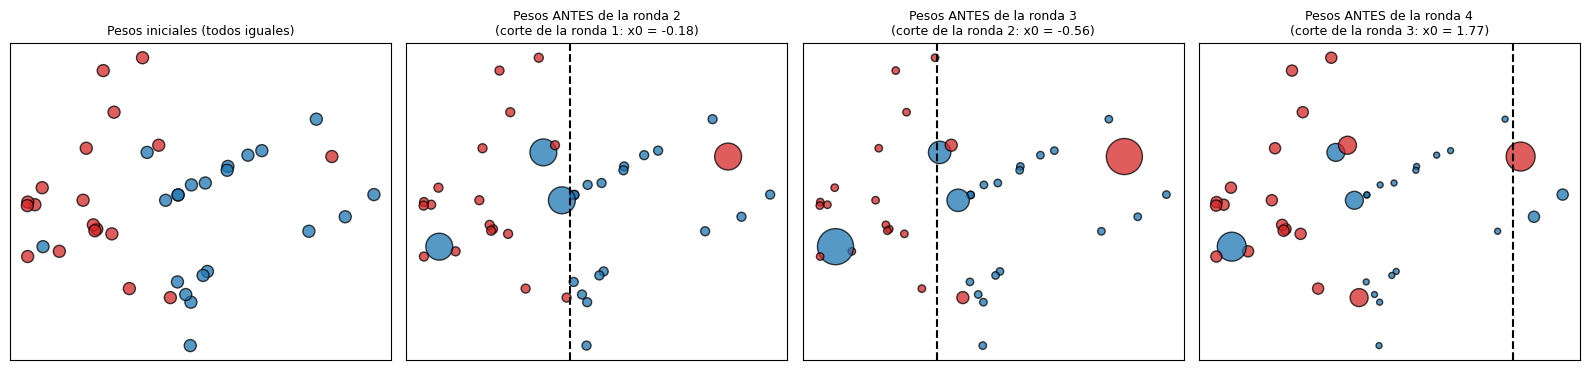

In [ ]:
# Visualizamos cómo cambian los pesos: el tamaño de cada punto es proporcional a su peso
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
for k, ax in enumerate(axs):
    tam = 3000 * historial_pesos[k]
    ax.scatter(X_ab[:, 0], X_ab[:, 1], c=T_ab, cmap=CMAP_PUNTOS, s=tam, edgecolor="k", alpha=0.75)
    if k > 0:
        st = stumps[k - 1]
        f, u = st.tree_.feature[0], st.tree_.threshold[0]
        (ax.axvline if f == 0 else ax.axhline)(u, color="k", ls="--")
        ax.set_title(f"Pesos ANTES de la ronda {k+1}\n(corte de la ronda {k}: x{f} = {u:.2f})", fontsize=9)
    else:
        ax.set_title("Pesos iniciales (todos iguales)", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### AdaBoost en scikit-learn (código de la diapositiva) — ⚠️ con una trampa
En la diapositiva el estimador base es `DecisionTreeClassifier()` **sin límite de profundidad**. Un árbol completo clasifica perfecto el train ⇒ $\varepsilon = 0$ ⇒ AdaBoost **se detiene en el primer modelo**: no hay errores que corregir. Miremos:

In [ ]:
base = DecisionTreeClassifier()              # tal cual la diapositiva: árbol completo
ada = AdaBoostClassifier(estimator=base, n_estimators=500, random_state=SEED)
model = ada.fit(Xbc_train, Tbc_train)
print("Modelos realmente entrenados:", len(model.estimators_))
print("Pesos (primeros 5):", model.estimator_weights_[:5])
print("Errores (primeros 5):", model.estimator_errors_[:5])
print("\n=> Con un árbol completo, AdaBoost equivale a UN solo árbol. Usá modelos DÉBILES.")

Modelos realmente entrenados: 1
Pesos (primeros 5): [1. 0. 0. 0. 0.]
Errores (primeros 5): [0. 1. 1. 1. 1.]

=> Con un árbol completo, AdaBoost equivale a UN solo árbol. Usá modelos DÉBILES.


Modelos entrenados: 500
Pesos alpha de los primeros 10: [1.239 1.109 0.696 0.619 0.677 0.595 0.521 0.469 0.461 0.372]
Accuracy test: 0.958
predict_proba (5 filas):
 [[0.373 0.627]
 [0.739 0.261]
 [0.451 0.549]
 [0.428 0.572]
 [0.441 0.559]]


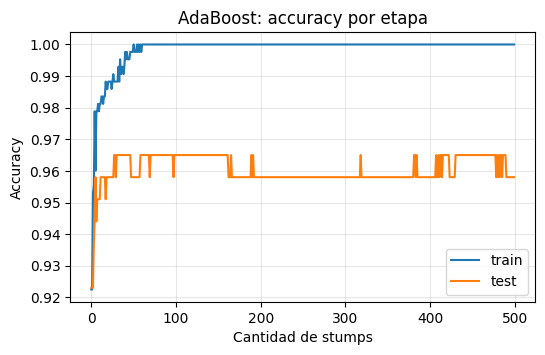

In [ ]:
# Forma recomendada: stumps (max_depth=1) o árboles poco profundos
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                         n_estimators=500, learning_rate=0.5, random_state=SEED)
model = ada.fit(Xbc_train, Tbc_train)

print("Modelos entrenados:", len(model.estimators_))
print("Pesos alpha de los primeros 10:", np.round(model.estimator_weights_[:10], 3))
print("Accuracy test:", round(model.score(Xbc_test, Tbc_test), 3))
print("predict_proba (5 filas):\n", np.round(model.predict_proba(Xbc_test)[:5], 3))

# staged_score: accuracy después de agregar cada modelo -> curva de aprendizaje del boosting
acc_train = list(model.staged_score(Xbc_train, Tbc_train))
acc_test = list(model.staged_score(Xbc_test, Tbc_test))
plt.figure(figsize=(6, 3.5))
plt.plot(acc_train, label="train"); plt.plot(acc_test, label="test")
plt.xlabel("Cantidad de stumps"); plt.ylabel("Accuracy"); plt.title("AdaBoost: accuracy por etapa")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Hiperparámetros clave de `AdaBoostClassifier`:** `estimator` (débil!), `n_estimators`, `learning_rate` (achica cada $\alpha$; menor ⇒ más modelos necesarios pero más robusto). Hay un *trade-off* entre ambos: si bajás `learning_rate`, subí `n_estimators`.

> En versiones recientes de scikit-learn el algoritmo `"SAMME.R"` fue eliminado; sólo queda `SAMME`, así que no hace falta pasar `algorithm=`.

---
## 6. Gradient Boosting

### Idea
1. Arrancar con una predicción muy simple (el modelo "más débil de todos").
2. Calcular el **residuo** de cada muestra: $\text{residuo} = T - \text{predicción}$.
3. Entrenar un **árbol de regresión** que prediga esos residuos.
4. Sumar ese árbol (multiplicado por `learning_rate`) a la predicción.
5. Repetir un número prefijado de veces.

¿Por qué "gradiente"? Con pérdida log-loss, el residuo $T - p$ es exactamente el **gradiente negativo** de la pérdida. Cada árbol da "un paso" de descenso por gradiente en el espacio de funciones.

### Fórmulas para clasificación binaria (las de las diapositivas)
* Probabilidad inicial y log-odds:
  $\displaystyle p_0 = \frac{\#\text{clase 1}}{\#\text{total}}, \qquad F_0 = \ln\!\left(\frac{\#\text{clase 1}}{\#\text{clase 0}}\right)$
* Valor de cada hoja $j$ del árbol: $\displaystyle \gamma_j = \frac{\sum_{i \in j} r_i}{\sum_{i \in j} p_i(1-p_i)}$
* Actualización: $F_i \leftarrow F_i + \eta \cdot \gamma_{j(i)}$  y  $p_i = \dfrac{1}{1+e^{-F_i}}$
* Predicción final: $\text{pred} = F_0 + \sum_{m=1}^{M} \eta\,\gamma^{(m)}$ → se pasa por la sigmoide y se redondea (≥ 0,5 ⇒ clase 1).

### Ejemplo de las diapositivas, recalculado
Dataset de 8 muestras (5 de clase 1 y 3 de clase 0).

> 📝 **Fe de erratas de la diapositiva:** dice $\text{Prob}_{inicial} = 5/9 = 0625$; lo correcto es $5/8 = 0{,}625$ (hay 8 muestras).

In [ ]:
gb_df = pd.DataFrame({
    "No": [1, 2, 3, 4, 5, 6, 7, 8],
    "X":  [40, 51, 28, 61, 59, 14, 30, 17],
    "Y":  [52, 69, 14, 72, 34, 85, 73, 69],
    "T":  [1, 1, 1, 1, 1, 0, 0, 0],
})
n1, n0 = (gb_df["T"] == 1).sum(), (gb_df["T"] == 0).sum()
p0 = n1 / len(gb_df)
F0 = np.log(n1 / n0)
print(f"Prob inicial = {n1}/{len(gb_df)} = {p0:.3f}")
print(f"log(odds) base = ln({n1}/{n0}) = {F0:.3f}")

gb_df["Prob_inicial"] = p0
gb_df["residuo"] = gb_df["T"] - p0
gb_df

Prob inicial = 5/8 = 0.625
log(odds) base = ln(5/3) = 0.511


,No,X,Y,T,Prob_inicial,residuo
0,1,40,52,1,0.625,0.375
1,2,51,69,1,0.625,0.375
2,3,28,14,1,0.625,0.375
3,4,61,72,1,0.625,0.375
4,5,59,34,1,0.625,0.375
5,6,14,85,0,0.625,-0.625
6,7,30,73,0,0.625,-0.625
7,8,17,69,0,0.625,-0.625


#### Paso 1: elegir el corte del árbol de regresión
Para cada corte candidato se calcula el error cuadrático de predecir los residuos con el **promedio de cada hoja**; se elige el de menor error. Comparamos los dos cortes de la diapositiva:

In [ ]:
def error_cuadratico_corte(df, columna, umbral):
    izq = df[df[columna] < umbral]["residuo"]
    der = df[df[columna] >= umbral]["residuo"]
    ecm = ((izq - izq.mean())**2).sum() + ((der - der.mean())**2).sum()
    return ecm, izq.mean(), der.mean(), len(izq), len(der)

for col, u in [("X", 39), ("Y", 43)]:
    ecm, mi, md_, ni, nd = error_cuadratico_corte(gb_df, col, u)
    print(f"Si {col} < {u}:  izq n={ni} prom={mi:+.3f} | der n={nd} prom={md_:+.3f} | suma err² = {ecm:.3f}")
print("\n=> Gana 'X < 39' (menor error). Separa perfectamente los residuos: grupo {3,6,7,8} y grupo {1,2,4,5}.")

Si X < 39:  izq n=4 prom=-0.375 | der n=4 prom=+0.375 | suma err² = 0.750
Si Y < 43:  izq n=2 prom=+0.375 | der n=6 prom=-0.125 | suma err² = 1.500

=> Gana 'X < 39' (menor error). Separa perfectamente los residuos: grupo {3,6,7,8} y grupo {1,2,4,5}.


> 📝 En la diapositiva las hojas de "Si X < 39" figuran ambas con 0.375; el promedio del residuo en la hoja izquierda (muestras 3, 6, 7, 8) es en realidad $(0{,}375 - 3\cdot 0{,}625)/4 = -0{,}375$. Lo importante (el error cuadrático menor y la elección de X < 39) no cambia.

#### Paso 2: valor de cada hoja y nuevas probabilidades

In [ ]:
lr = 0.5    # con learning_rate = 0.5 se obtienen exactamente los números de la diapositiva

def un_paso_gb(F, T, hoja_izq, lr):
    p = 1 / (1 + np.exp(-F))
    r = T - p
    F_nuevo = F.copy()
    for mascara in [hoja_izq, ~hoja_izq]:
        gamma = r[mascara].sum() / (p[mascara] * (1 - p[mascara])).sum()
        F_nuevo[mascara] += lr * gamma
    return F_nuevo

T = gb_df["T"].values
hoja_izq = (gb_df["X"] < 39).values
F = np.full(len(T), F0)

# Valor de las hojas en el primer paso
p = 1 / (1 + np.exp(-F)); r = T - p
for nombre, m in [("X < 39 ", hoja_izq), ("X >= 39", ~hoja_izq)]:
    print(f"Hoja {nombre}: Valor = {r[m].sum():+.3f} / {(p[m]*(1-p[m])).sum():.4f} = {r[m].sum()/(p[m]*(1-p[m])).sum():+.2f}")

F = un_paso_gb(F, T, hoja_izq, lr)
gb_df["log_odds_1"] = F.round(3)
gb_df["Prob_1"] = (1 / (1 + np.exp(-F))).round(3)
gb_df["residuo_1"] = (T - 1 / (1 + np.exp(-F))).round(3)
gb_df[["No", "X", "Y", "T", "log_odds_1", "Prob_1", "residuo_1"]]

Hoja X < 39 : Valor = -1.500 / 0.9375 = -1.60
Hoja X >= 39: Valor = +1.500 / 0.9375 = +1.60


,No,X,Y,T,log_odds_1,Prob_1,residuo_1
0,1,40,52,1,1.311,0.788,0.212
1,2,51,69,1,1.311,0.788,0.212
2,3,28,14,1,-0.289,0.428,0.572
3,4,61,72,1,1.311,0.788,0.212
4,5,59,34,1,1.311,0.788,0.212
5,6,14,85,0,-0.289,0.428,-0.428
6,7,30,73,0,-0.289,0.428,-0.428
7,8,17,69,0,-0.289,0.428,-0.428


Coincide con la diapositiva: log-odds **1,310 / −0,289** y probabilidades **0,787 / 0,428** (diferencias de redondeo en el 3er decimal).

#### Paso 3: repetir — la tabla Prob1 … Prob6 de la diapositiva
La diapositiva **reutiliza siempre el mismo corte (X < 39)**. Haciéndolo así reproducimos su tabla:

In [ ]:
F = np.full(len(T), F0)
tabla = {"Prob_inicial": 1 / (1 + np.exp(-F))}
for m in range(1, 7):
    F = un_paso_gb(F, T, hoja_izq, lr)
    tabla[f"Prob{m}"] = 1 / (1 + np.exp(-F))
pd.DataFrame(tabla, index=gb_df["No"]).round(3)

,Prob_inicial,Prob1,Prob2,Prob3,Prob4,Prob5,Prob6
No,,,,,,,
1,0.625,0.788,0.875,0.925,0.955,0.973,0.984
2,0.625,0.788,0.875,0.925,0.955,0.973,0.984
3,0.625,0.428,0.342,0.298,0.274,0.262,0.256
4,0.625,0.788,0.875,0.925,0.955,0.973,0.984
5,0.625,0.788,0.875,0.925,0.955,0.973,0.984
6,0.625,0.428,0.342,0.298,0.274,0.262,0.256
7,0.625,0.428,0.342,0.298,0.274,0.262,0.256
8,0.625,0.428,0.342,0.298,0.274,0.262,0.256


Observá que la **muestra 3** (X=28, clase 1) cae en la hoja de las clases 0 y su probabilidad **baja** en cada paso: con un único corte fijo el modelo nunca puede corregirla. Por eso el algoritmo real **vuelve a buscar el mejor corte en cada iteración** (los residuos cambian ⇒ el árbol cambia).

#### Implementación manual completa vs. `GradientBoostingClassifier`
Ahora en cada ronda entrenamos un árbol de regresión nuevo sobre los residuos actuales. Tiene que coincidir con scikit-learn:

In [ ]:
Xg = gb_df[["X", "Y"]].values
F = np.full(len(T), F0)
arboles = []
for m in range(6):
    p = 1 / (1 + np.exp(-F))
    r = T - p                                                   # residuos actuales
    arbol_r = DecisionTreeRegressor(max_depth=1, criterion="friedman_mse", random_state=0).fit(Xg, r)
    hojas = arbol_r.apply(Xg)                                   # en qué hoja cae cada muestra
    valores = {}
    for h in np.unique(hojas):
        msk = hojas == h
        valores[h] = r[msk].sum() / (p[msk] * (1 - p[msk])).sum()  # valor de la hoja
        F[msk] += lr * valores[h]
    arboles.append((arbol_r, valores))
    f, u = arbol_r.tree_.feature[0], arbol_r.tree_.threshold[0]
    print(f"Árbol {m+1}: corte {'XY'[f]} <= {u:5.1f}  ->  probs = {np.round(1/(1+np.exp(-F)), 3)}")

gbc_demo = GradientBoostingClassifier(n_estimators=6, learning_rate=0.5, max_depth=1).fit(Xg, T)
print("\nscikit-learn Prob6     ->", np.round(gbc_demo.predict_proba(Xg)[:, 1], 3))

Árbol 1: corte X <=  35.0  ->  probs = [0.788 0.788 0.428 0.788 0.788 0.428 0.428 0.428]
Árbol 2: corte Y <=  72.5  ->  probs = [0.851 0.851 0.535 0.851 0.851 0.238 0.238 0.535]
Árbol 3: corte X <=  22.5  ->  probs = [0.898 0.898 0.641 0.898 0.898 0.113 0.326 0.319]
Árbol 4: corte Y <=  60.5  ->  probs = [0.946 0.857 0.779 0.857 0.946 0.08  0.248 0.242]
Árbol 5: corte Y <=  72.5  ->  probs = [0.958 0.887 0.821 0.887 0.958 0.044 0.149 0.293]
Árbol 6: corte X <=  22.5  ->  probs = [0.969 0.914 0.862 0.914 0.969 0.023 0.192 0.174]

scikit-learn Prob6     -> [0.969 0.914 0.862 0.914 0.969 0.023 0.192 0.174]


#### Predicción de muestras nuevas (101 y 102 de la diapositiva)
$\text{pred} = F_0 + \sum \eta\cdot\text{Valor}_{\text{árbol}_i}$ → sigmoide → redondeo.

In [ ]:
nuevas = np.array([[61, 37], [17, 69]])
pred = np.full(len(nuevas), F0)
for arbol_r, valores in arboles:
    hojas = arbol_r.apply(nuevas)
    pred += lr * np.array([valores[h] for h in hojas])
prob = 1 / (1 + np.exp(-pred))
print(pd.DataFrame({"No": [101, 102], "X": nuevas[:, 0], "Y": nuevas[:, 1],
                    "pred (log-odds)": pred.round(3), "Prob": prob.round(3),
                    "Respuesta": (prob >= 0.5).astype(int)}))
print("\nscikit-learn decision_function:", gbc_demo.decision_function(nuevas).round(3))

    No   X   Y  pred (log-odds)   Prob  Respuesta
0  101  61  37            3.432  0.969          1
1  102  17  69           -1.555  0.174          0

scikit-learn decision_function: [ 3.432 -1.555]


> El primer árbol de scikit-learn corta en **X ≤ 35** (pone el umbral en el punto medio entre 30 y 40): separa exactamente los mismos grupos que "X < 39" de la diapositiva. Desde el árbol 2 los cortes cambian porque cambian los residuos.

Los números exactos difieren de la diapositiva (4,085 / −0,344) porque ella usa árboles distintos, pero la **conclusión es la misma**: 101 → clase 1, 102 → clase 0.

### Gradient Boosting en scikit-learn
**Hiperparámetros clave:**
| Parámetro | Efecto |
|---|---|
| `n_estimators` | Nº de árboles. **Demasiados ⇒ sobreajuste** (a diferencia de RF). |
| `learning_rate` | Tamaño del paso. Valores chicos (0,01–0,1) + más árboles suelen generalizar mejor. |
| `max_depth` / `max_leaf_nodes` | Complejidad de cada árbol (típico 3–8; la diapositiva menciona 8–32 hojas). |
| `subsample` | < 1 ⇒ *Stochastic Gradient Boosting*: cada árbol usa una fracción de filas (reduce varianza). |
| `n_iter_no_change`, `validation_fraction` | *Early stopping*: corta cuando la validación deja de mejorar. |

Para datasets grandes, scikit-learn tiene `HistGradientBoostingClassifier` (mucho más rápido, maneja `NaN`).

In [ ]:
gbc = GradientBoostingClassifier(loss="log_loss", learning_rate=0.1, max_depth=3, n_estimators=50,
                                 random_state=SEED)
model = gbc.fit(Xbc_train, Tbc_train)
print("Accuracy test:", round(model.score(Xbc_test, Tbc_test), 3))
print(np.round(model.predict_proba(Xbc_test)[:5], 3))

Accuracy test: 0.944


[[0.005 0.995]
 [0.993 0.007]
 [0.435 0.565]
 [0.026 0.974]
 [0.068 0.932]]


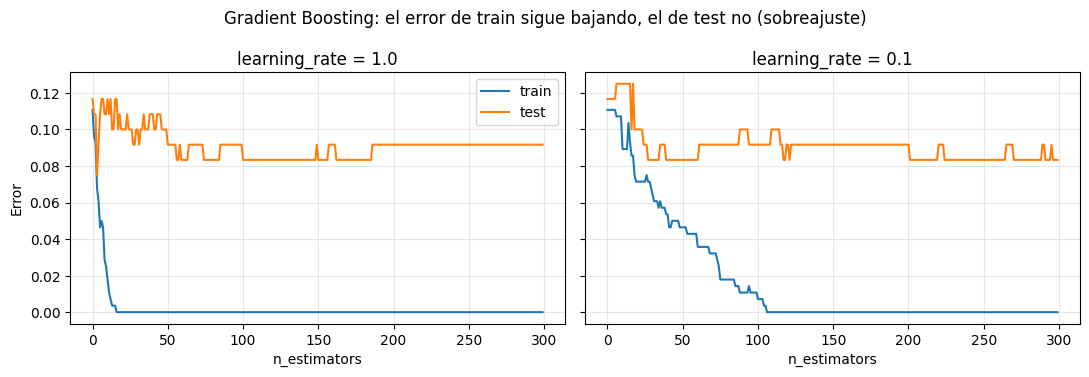

In [ ]:
# Efecto del learning_rate y del número de árboles (curvas con staged_predict)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for i, lr_ in enumerate([1.0, 0.1]):
    g = GradientBoostingClassifier(n_estimators=300, learning_rate=lr_, max_depth=3,
                                   random_state=SEED).fit(Xm_train, Tm_train)
    err_tr = [1 - accuracy_score(Tm_train, p) for p in g.staged_predict(Xm_train)]
    err_te = [1 - accuracy_score(Tm_test, p) for p in g.staged_predict(Xm_test)]
    ax[i].plot(err_tr, label="train"); ax[i].plot(err_te, label="test")
    ax[i].set_title(f"learning_rate = {lr_}"); ax[i].set_xlabel("n_estimators"); ax[i].grid(alpha=0.3)
ax[0].set_ylabel("Error"); ax[0].legend()
plt.suptitle("Gradient Boosting: el error de train sigue bajando, el de test no (sobreajuste)")
plt.tight_layout(); plt.show()

---
## 7. XGBoost y LightGBM

Son implementaciones **optimizadas** de Gradient Boosting, muy usadas en competencias (Kaggle) y en la industria.

| Característica | XGBoost (`XGBClassifier`) | LightGBM (`LGBMClassifier`) |
|---|---|---|
| Crecimiento del árbol | **Por niveles** (*level-wise*) por defecto | **Por hojas** (*leaf-wise*): expande la hoja que más reduce la pérdida |
| Fortalezas | Regularización L1/L2 incorporada, robusto, maneja `NaN` | Muy rápido y con poca memoria (agrupa valores en *bins*/histogramas) |
| Riesgo | — | Puede sobreajustar en datasets **chicos** (controlar `num_leaves`, `min_child_samples`) |
| Parámetros clave | `n_estimators`, `learning_rate`, `max_depth`, `subsample`, `colsample_bytree`, `reg_lambda` | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree` |

⚠️ **Trampa frecuente con XGBoost:** exige que las clases sean `0, 1, …, K-1`. El dataset *glass* tiene clases `1, 2, 3, 5, 6, 7` ⇒ hay que codificarlas con `LabelEncoder` (lo hacemos en la práctica).

In [ ]:
if HAY_XGB:
    xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                        subsample=0.9, colsample_bytree=0.9, random_state=SEED, verbosity=0)
    xgb.fit(Xbc_train, Tbc_train)
    print("XGBoost  accuracy test:", round(xgb.score(Xbc_test, Tbc_test), 3))
if HAY_LGBM:
    lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.1, num_leaves=15,
                          random_state=SEED, verbose=-1)
    lgbm.fit(Xbc_train, Tbc_train)
    print("LightGBM accuracy test:", round(lgbm.score(Xbc_test, Tbc_test), 3))

XGBoost  accuracy test: 0.965
LightGBM accuracy test: 0.958


---
## 8. Stacking (*Stacked Generalization*)

* Usa **estimadores de naturaleza distinta** (árboles, regresión logística, SVM, Naïve Bayes, KNN, redes…). Se los llama estimadores **"base"**.
* Introduce el **meta-aprendizaje**: un **meta-estimador** aprende *a partir de las predicciones* de los modelos base ("aprende lo aprendido").
* El meta-estimador puede ser **cualquier** modelo, ¡incluso otro ensamble!

### ¿Cómo se arma el nuevo dataset? (lo importante para el examen)
Si los modelos base predijeran sobre **los mismos datos con los que se entrenaron**, sus predicciones serían demasiado optimistas y el meta-modelo aprendería a confiar en el que más memorizó. Por eso `StackingClassifier`:

1. Para armar el dataset del meta-modelo usa **predicciones *out-of-fold*** (`cross_val_predict` con `cv` particiones): cada fila es predicha por un modelo que **no la vio**.
2. Entrena el **meta-estimador** con esas predicciones como atributos (columnas *Pred. RL, Pred. SVM, …* de la diapositiva).
3. **Re-entrena los modelos base con todo el train** para usarlos al predecir datos nuevos.

| Parámetro | Significado |
|---|---|
| `estimators` | Lista de tuplas `(nombre, modelo)` |
| `final_estimator` | Meta-estimador (default: `LogisticRegression`) |
| `cv` | Particiones de validación cruzada para generar las predicciones *out-of-fold* (default 5) |
| `passthrough` | `True` ⇒ el meta-estimador recibe **predicciones + atributos originales** |
| `stack_method` | Qué salida usar de cada base: `"auto"` (prioriza `predict_proba`), `"predict_proba"`, `"decision_function"`, `"predict"` |

### Construyendo el dataset del meta-modelo "a mano"

In [ ]:
modelos_base = {
    "RL":  make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM": make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
    "RF":  RandomForestClassifier(n_estimators=200, random_state=SEED),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "NB":  GaussianNB(),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

meta_X = pd.DataFrame(index=Xbc_train.index)
for nombre, mod in modelos_base.items():
    # probabilidad de clase 1 predicha por un modelo que NO vio esa fila
    meta_X[f"Pred_{nombre}"] = cross_val_predict(mod, Xbc_train, Tbc_train, cv=cv5,
                                                 method="predict_proba")[:, 1]
meta_X["T"] = Tbc_train.values
print("Nuevo dataset para el meta-estimador (como la tabla de la diapositiva):")
meta_X.head().round(3)

Nuevo dataset para el meta-estimador (como la tabla de la diapositiva):


,Pred_RL,Pred_SVM,Pred_RF,Pred_KNN,Pred_NB,T
517,0.000,0.000,0.015,0.0,0.0,0
287,1.000,0.995,0.995,1.0,1.0,1
25,0.000,0.018,0.005,0.0,0.0,0
253,0.004,0.002,0.015,0.0,0.0,0
369,0.000,0.006,0.005,0.0,0.0,0


In [ ]:
# Entrenamos el meta-estimador sobre esas columnas
meta = LogisticRegression().fit(meta_X.drop(columns="T"), meta_X["T"])
print("Coeficientes del meta-modelo (cuánto 'confía' en cada base):")
print(pd.Series(meta.coef_[0], index=meta_X.columns[:-1]).round(3))

Coeficientes del meta-modelo (cuánto 'confía' en cada base):
Pred_RL     3.131
Pred_SVM    2.024
Pred_RF     1.913
Pred_KNN    1.295
Pred_NB     0.401
dtype: float64


### Stacking con scikit-learn (código de la diapositiva, con escalado)
> **Buena práctica:** KNN, SVM y Regresión Logística son sensibles a la escala ⇒ envolverlos en un `Pipeline` con `StandardScaler`. Los árboles no lo necesitan.

In [ ]:
base_learners = [
    ("bl1", DecisionTreeClassifier(max_depth=4, random_state=SEED)),
    ("bl2", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
    ("bl3", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
]
stck = StackingClassifier(estimators=base_learners,
                          final_estimator=RandomForestClassifier(random_state=SEED))
model = stck.fit(Xbc_train, Tbc_train)
print("Accuracy test stacking:", round(model.score(Xbc_test, Tbc_test), 3))
print(np.round(model.predict_proba(Xbc_test)[:5], 3))

# Cada base por separado, para comparar
for nombre, est in model.named_estimators_.items():
    print(f"  {nombre}: accuracy test = {est.score(Xbc_test, Tbc_test):.3f}")

Accuracy test stacking: 0.972
[[0.   1.  ]
 [1.   0.  ]
 [0.39 0.61]
 [0.11 0.89]
 [0.94 0.06]]
  bl1: accuracy test = 0.944
  bl2: accuracy test = 0.979
  bl3: accuracy test = 0.986


In [ ]:
# cv y passthrough
stck_pt = StackingClassifier(estimators=base_learners,
                             final_estimator=RandomForestClassifier(random_state=SEED),
                             cv=10,               # 10 particiones para las predicciones out-of-fold
                             passthrough=True)    # meta-modelo recibe predicciones + atributos originales
stck_pt.fit(Xbc_train, Tbc_train)
print("Accuracy test (cv=10, passthrough=True):", round(stck_pt.score(Xbc_test, Tbc_test), 3))

# ¿Qué columnas recibe el meta-estimador?
Z = stck_pt.transform(Xbc_test.iloc[:2])
print("Columnas que ve el meta-estimador:", Z.shape[1],
      "= 3 predicciones (binario: 1 prob por modelo) + 30 atributos originales")

Accuracy test (cv=10, passthrough=True): 0.979
Columnas que ve el meta-estimador: 33 = 3 predicciones (binario: 1 prob por modelo) + 30 atributos originales


### Stacking de múltiples capas — *¿Cómo está conformado este stacking?* (pregunta de la diapositiva)

```python
base_learners_1 = [('bl1', DecisionTreeClassifier(max_depth=4)), ('bl2', LogisticRegression())]
base_learners_2 = [('bl3', KNeighborsClassifier(n_neighbors=5)), ('bl4', LinearRegression())]
stck_2 = StackingClassifier(estimators=base_learners_2, final_estimator=RandomForestClassifier())
stck_1 = StackingClassifier(estimators=base_learners_1, final_estimator=stck_2)
```

**Respuesta:** el final_estimator de `stck_1` es a su vez otro stacking. Leído desde los datos hacia la salida:

```
            X (atributos originales)
              │
   ┌──────────┴──────────┐
   ▼                     ▼
 Árbol (bl1)        Reg. Logística (bl2)        ◄ CAPA 1  (base de stck_1)
   │                     │
   └──── predicciones ───┘   (2 columnas en binario)
              │
   ┌──────────┴──────────┐
   ▼                     ▼
 KNN (bl3)         LinearRegression (bl4)       ◄ CAPA 2  (base de stck_2)
   │                     │
   └──── predicciones ───┘
              │
              ▼
       RandomForest                              ◄ CAPA 3  (meta-estimador final)
              │
              ▼
       Predicción final
```

* La **capa 2** (KNN y LinearRegression) **no ve los atributos originales**: sólo ve las predicciones de la capa 1 (salvo que se use `passthrough=True`).
* ⚠️ Usar **`LinearRegression`** (un regresor) dentro de un `StackingClassifier` es conceptualmente dudoso: scikit-learn lo permite (usa su `predict`), pero predice un número continuo, no una clase. Sólo tiene sentido en casos especiales (ej. clases ordinales). En la práctica conviene `LogisticRegression`.

In [ ]:
from sklearn.linear_model import LinearRegression

base_learners_1 = [("bl1", DecisionTreeClassifier(max_depth=4, random_state=SEED)),
                   ("bl2", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))]
base_learners_2 = [("bl3", KNeighborsClassifier(n_neighbors=5)),
                   ("bl4", LinearRegression())]
stck_2 = StackingClassifier(estimators=base_learners_2, final_estimator=RandomForestClassifier(random_state=SEED))
stck_1 = StackingClassifier(estimators=base_learners_1, final_estimator=stck_2)
model = stck_1.fit(Xbc_train, Tbc_train)
print("Accuracy test stacking de 3 capas:", round(model.score(Xbc_test, Tbc_test), 3))
print("Capa 1:", list(model.named_estimators_.keys()))
print("Capa 2:", list(model.final_estimator_.named_estimators_.keys()))
print("Capa 3:", type(model.final_estimator_.final_estimator_).__name__)

Accuracy test stacking de 3 capas: 0.979
Capa 1: ['bl1', 'bl2']
Capa 2: ['bl3', 'bl4']
Capa 3: RandomForestClassifier


---
## 9. Bonus: `VotingClassifier`
Es como un stacking **sin meta-modelo**: combina modelos distintos con una regla fija.
* `voting="hard"`: gana la clase más votada.
* `voting="soft"`: se promedian probabilidades (suele funcionar mejor si los modelos están bien calibrados).

Si el stacking no supera a un voting simple, probablemente el meta-modelo no está aportando.

In [ ]:
for tipo in ["hard", "soft"]:
    vot = VotingClassifier(estimators=base_learners, voting=tipo).fit(Xbc_train, Tbc_train)
    print(f"Voting {tipo:4s}: accuracy test = {vot.score(Xbc_test, Tbc_test):.3f}")

Voting hard: accuracy test = 0.979
Voting soft: accuracy test = 0.958


---
## 10. Comparación visual de fronteras de decisión
Mismo dataset 2D, distintos modelos. Observá: el árbol solo es "dentado"; bagging/RF suavizan; AdaBoost con stumps arma la frontera con cortes rectos; Gradient Boosting y Stacking quedan intermedios.

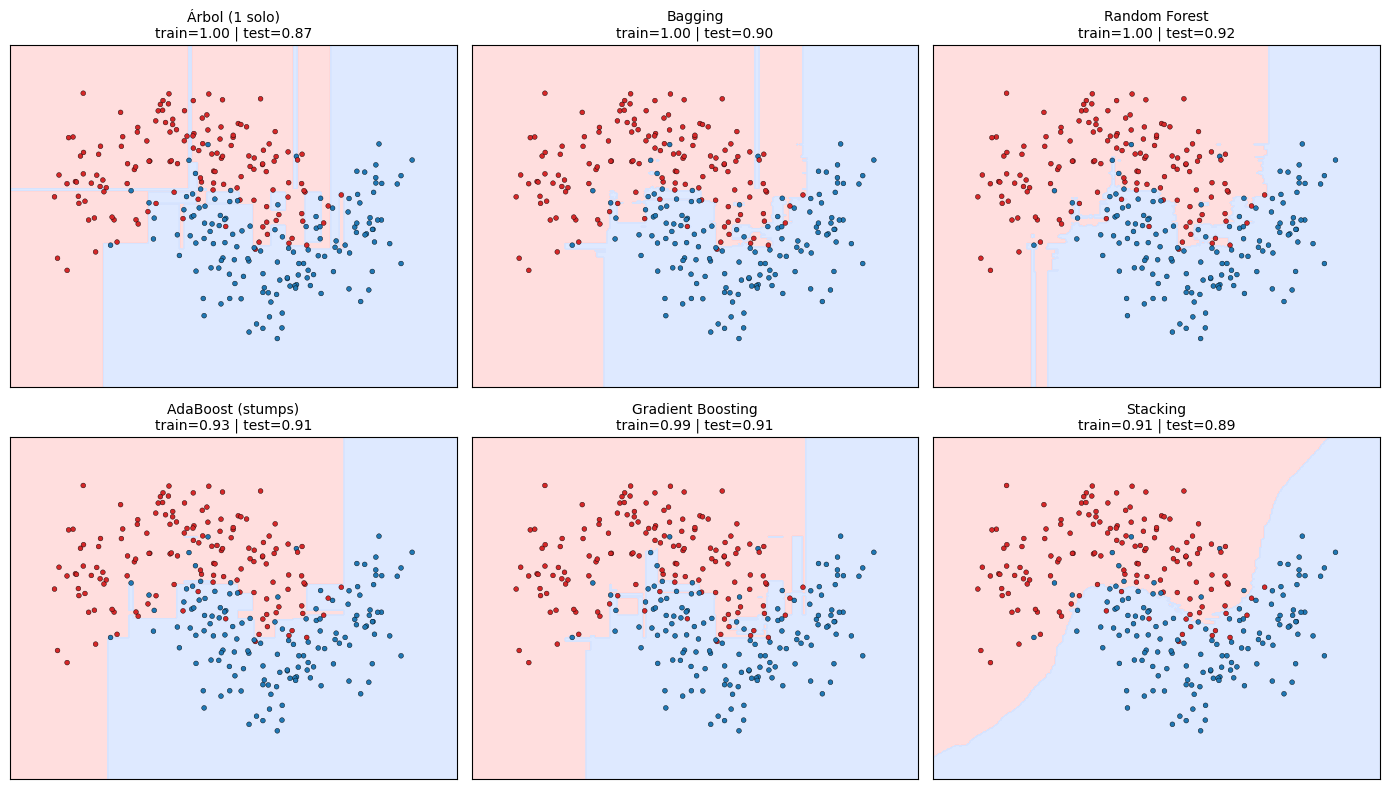

In [ ]:
modelos_vis = {
    "Árbol (1 solo)": DecisionTreeClassifier(random_state=SEED),
    "Bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "AdaBoost (stumps)": AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=SEED),
    "Stacking": StackingClassifier(
        estimators=[("dt", DecisionTreeClassifier(max_depth=4)),
                    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(15))),
                    ("svm", make_pipeline(StandardScaler(), SVC(probability=True)))],
        final_estimator=LogisticRegression()),
}
fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, (nombre, mod) in zip(axs.ravel(), modelos_vis.items()):
    mod.fit(Xm_train, Tm_train)
    graficar_frontera(mod, Xm_train, Tm_train, ax,
                      f"{nombre}\ntrain={mod.score(Xm_train, Tm_train):.2f} | test={mod.score(Xm_test, Tm_test):.2f}")
plt.tight_layout(); plt.show()

---
## 11. 🧪 Práctica guiada — Actividad 2

> **Consigna:** Utilice la base de datos **"glass"**, separando en **90-10**. Entrene un **AdaBoost**, un **Gradient Boosting** y un **Stacking** (con al menos **cuatro** estimadores base). Calcule e imprima **accuracy, precision, recall, f-score y AUC-ROC**. Repita los cálculos **10 veces**, cambiando el `random_state` en el split. Calcule el **promedio e IC 95 %** de cada métrica. Compare con los de la actividad 1.

### Antes de empezar: cosas a tener en cuenta con *glass*
* **214 muestras, 9 atributos** (índice de refracción y óxidos: Na, Mg, Al, Si, K, Ca, Ba, Fe) y **6 clases** de vidrio: `1, 2, 3, 5, 6, 7` (la 4 no existe).
* Es **multiclase y desbalanceado** (la clase 6 tiene sólo 9 muestras). Con un test del 10 % (≈ 22 muestras) **conviene `stratify=T`** para que estén todas las clases en test.
* **Métricas multiclase:** precision/recall/F1 necesitan `average=` → `"macro"` (todas las clases pesan igual; recomendable con desbalance) o `"weighted"`. AUC-ROC necesita `multi_class="ovr"` (uno contra el resto) y la matriz de `predict_proba`.
* Codificamos las clases a `0..5` con `LabelEncoder` (requisito de XGBoost; no afecta al resto).
* Con sólo 22 muestras de test las métricas **varían mucho** entre repeticiones: por eso se piden 10 repeticiones y un intervalo de confianza.

### 11.1 Cargar el dataset
En Colab podés usar tu archivo del Drive (como en tu notebook) o descargarlo de internet.

In [ ]:
COLUMNAS = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
URL_GLASS = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/glass.csv"

def cargar_glass(ruta=None):
    # Carga glass desde una ruta local/Drive o, si no se indica, desde internet.
    df = pd.read_csv(ruta if ruta else URL_GLASS, header=None)
    if df.shape[1] == 11:              # la versión original de UCI trae una columna Id al inicio
        df = df.iloc[:, 1:]
    if not str(df.iloc[0, 0]).replace(".", "", 1).isdigit():   # si el archivo trae encabezado
        df = df.iloc[1:].astype(float)
    df.columns = COLUMNAS
    df["Type"] = df["Type"].astype(int)
    return df

# Opción Drive (descomentar en Colab):
# from google.colab import drive; drive.mount('/content/drive')
# glass = cargar_glass('/content/drive/MyDrive/.../glass.csv')
glass = cargar_glass()
print(glass.shape)
glass.head()

(214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


Distribución de clases:
Type
1    70
2    76
3    17
5    13
6     9
7    29
Name: count, dtype: int64


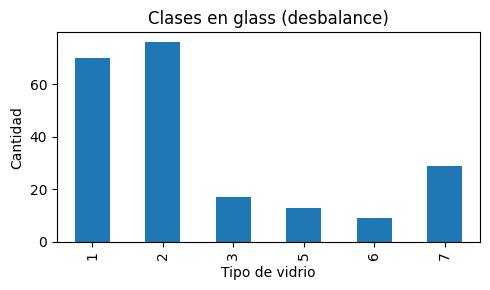

In [ ]:
print("Distribución de clases:")
print(glass["Type"].value_counts().sort_index())
glass["Type"].value_counts().sort_index().plot.bar(figsize=(5, 3), title="Clases en glass (desbalance)")
plt.xlabel("Tipo de vidrio"); plt.ylabel("Cantidad"); plt.tight_layout(); plt.show()

In [ ]:
feature_cols = glass.columns[:-1]
X = glass[feature_cols]
le = LabelEncoder()
T = pd.Series(le.fit_transform(glass["Type"]), name="Type")   # 1,2,3,5,6,7 -> 0..5
print("Codificación:", {int(c): i for i, c in enumerate(le.classes_)})

Codificación: {1: 0, 2: 1, 3: 2, 5: 3, 6: 4, 7: 5}


### 11.2 Definir los modelos
Funciones que devuelven un modelo **nuevo** en cada repetición (para no reutilizar uno ya entrenado).

In [ ]:
def crear_adaboost(seed):
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2),
                              n_estimators=300, learning_rate=0.5, random_state=seed)

def crear_gradient_boosting(seed):
    return GradientBoostingClassifier(loss="log_loss", learning_rate=0.1, max_depth=3,
                                      n_estimators=150, subsample=0.9, random_state=seed)

def crear_stacking(seed):
    base = [  # al menos 4 estimadores base de naturaleza distinta
        ("arbol", DecisionTreeClassifier(max_depth=5, random_state=seed)),
        ("knn",   make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
        ("svm",   make_pipeline(StandardScaler(), SVC(probability=True, random_state=seed))),
        ("rl",    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
        ("nb",    GaussianNB()),
    ]
    return StackingClassifier(estimators=base,
                              final_estimator=LogisticRegression(max_iter=2000),
                              cv=StratifiedKFold(5, shuffle=True, random_state=seed))

# Modelos de referencia (para comparar con la actividad 1: árbol / bagging / random forest)
def crear_arbol(seed):         return DecisionTreeClassifier(random_state=seed)
def crear_random_forest(seed): return RandomForestClassifier(n_estimators=500, random_state=seed, n_jobs=-1)

MODELOS = {
    "Árbol (ref.)": crear_arbol,
    "Random Forest (ref.)": crear_random_forest,
    "AdaBoost": crear_adaboost,
    "Gradient Boosting": crear_gradient_boosting,
    "Stacking": crear_stacking,
}
if HAY_XGB:
    MODELOS["XGBoost (extra)"] = lambda s: XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4,
                                                         random_state=s, verbosity=0)

### 11.3 Función de evaluación (las 5 métricas)

In [ ]:
def evaluar(modelo, X_test, T_test):
    T_pred = modelo.predict(X_test)
    T_proba = modelo.predict_proba(X_test)
    return {
        "accuracy":  accuracy_score(T_test, T_pred),
        "precision": precision_score(T_test, T_pred, average="macro", zero_division=0),
        "recall":    recall_score(T_test, T_pred, average="macro", zero_division=0),
        "f1":        f1_score(T_test, T_pred, average="macro", zero_division=0),
        "auc_roc":   roc_auc_score(T_test, T_proba, multi_class="ovr", average="macro",
                                   labels=modelo.classes_),
    }

# Prueba con una sola partición
X_train, X_test, T_train, T_test = train_test_split(X, T, test_size=0.1, stratify=T, random_state=0)
m = crear_adaboost(0).fit(X_train, T_train)
print({k: round(v, 3) for k, v in evaluar(m, X_test, T_test).items()})

{'accuracy': 0.773, 'precision': 0.609, 'recall': 0.618, 'f1': 0.582, 'auc_roc': 0.899}


### 11.4 Diez repeticiones cambiando el `random_state` del split

In [ ]:
SEMILLAS = range(10)
filas = []
for seed in SEMILLAS:
    X_train, X_test, T_train, T_test = train_test_split(
        X, T, test_size=0.1, stratify=T, random_state=seed)          # 90-10
    for nombre, crear in MODELOS.items():
        modelo = crear(seed).fit(X_train, T_train)
        filas.append({"modelo": nombre, "seed": seed, **evaluar(modelo, X_test, T_test)})

resultados = pd.DataFrame(filas)
print("Resultados por repetición (primeras filas):")
resultados.head(8).round(3)

Resultados por repetición (primeras filas):


,modelo,seed,accuracy,precision,recall,f1,auc_roc
0,Árbol (ref.),0,0.727,0.722,0.810,0.732,0.877
1,Random Forest (ref.),0,0.909,0.893,0.893,0.893,0.985
2,AdaBoost,0,0.773,0.609,0.618,0.582,0.899
3,Gradient Boosting,0,0.864,0.872,0.872,0.872,0.978
4,Stacking,0,0.773,0.575,0.622,0.596,0.952
5,XGBoost (extra),0,0.773,0.643,0.685,0.660,0.954
6,Árbol (ref.),1,0.636,0.762,0.762,0.734,0.837
7,Random Forest (ref.),1,0.773,0.897,0.827,0.848,0.953


### 11.5 Promedio e IC 95 %
Usamos la distribución **t de Student** con $n-1 = 9$ grados de libertad (con pocas repeticiones es más correcto que usar 1,96):

$$\bar{x} \pm t_{0.975,\,9}\cdot\frac{s}{\sqrt{10}}, \qquad t_{0.975,\,9}\approx 2{,}262$$

In [ ]:
METRICAS = ["accuracy", "precision", "recall", "f1", "auc_roc"]
resumen = []
for nombre in MODELOS:
    fila = {"modelo": nombre}
    for met in METRICAS:
        media, lo, hi = intervalo_confianza_95(resultados.loc[resultados.modelo == nombre, met])
        fila[met] = f"{media:.3f} [{lo:.3f}, {hi:.3f}]"
    resumen.append(fila)
tabla_resumen = pd.DataFrame(resumen).set_index("modelo")
print("Media [IC 95%] de cada métrica en 10 repeticiones:")
tabla_resumen

Media [IC 95%] de cada métrica en 10 repeticiones:


,accuracy,precision,recall,f1,auc_roc
modelo,,,,,
Árbol (ref.),"0.686 [0.626, 0.747]","0.662 [0.576, 0.748]","0.683 [0.603, 0.763]","0.653 [0.576, 0.730]","0.806 [0.761, 0.850]"
Random Forest (ref.),"0.818 [0.772, 0.864]","0.797 [0.703, 0.891]","0.775 [0.694, 0.856]","0.773 [0.683, 0.863]","0.957 [0.934, 0.980]"
AdaBoost,"0.714 [0.670, 0.757]","0.623 [0.547, 0.700]","0.613 [0.559, 0.667]","0.590 [0.527, 0.653]","0.925 [0.902, 0.948]"
Gradient Boosting,"0.805 [0.756, 0.853]","0.758 [0.681, 0.835]","0.763 [0.712, 0.815]","0.749 [0.687, 0.810]","0.951 [0.932, 0.969]"
Stacking,"0.727 [0.679, 0.776]","0.651 [0.566, 0.735]","0.665 [0.593, 0.737]","0.647 [0.571, 0.724]","0.922 [0.892, 0.953]"
XGBoost (extra),"0.764 [0.699, 0.828]","0.695 [0.580, 0.810]","0.692 [0.591, 0.794]","0.679 [0.569, 0.789]","0.948 [0.932, 0.964]"


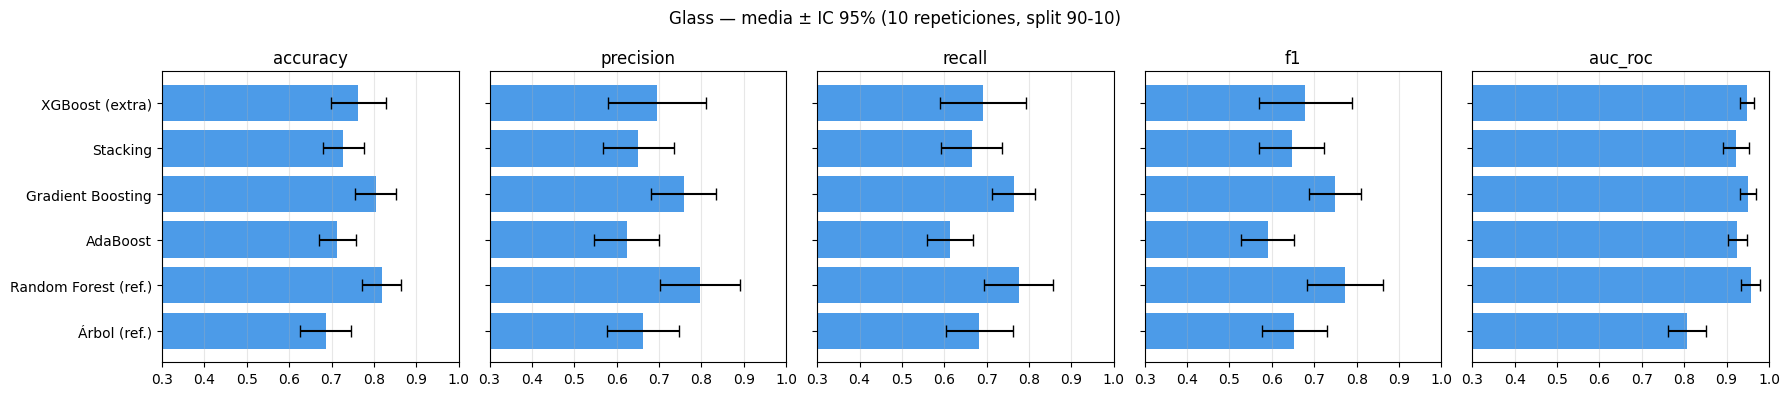

In [ ]:
# Gráfico: media ± IC 95% por métrica
fig, axs = plt.subplots(1, len(METRICAS), figsize=(18, 4), sharey=True)
nombres = list(MODELOS.keys())
for ax, met in zip(axs, METRICAS):
    medias, errores = [], []
    for nombre in nombres:
        media, lo, hi = intervalo_confianza_95(resultados.loc[resultados.modelo == nombre, met])
        medias.append(media); errores.append(hi - media)
    ax.barh(nombres, medias, xerr=errores, capsize=4, color="#4C9BE8")
    ax.set_title(met); ax.set_xlim(0.3, 1.0); ax.grid(axis="x", alpha=0.3)
plt.suptitle("Glass — media ± IC 95% (10 repeticiones, split 90-10)")
plt.tight_layout(); plt.show()

### 11.6 Comparación con la Actividad 1
Cargá en el diccionario los valores que obtuviste en la actividad 1 (media, IC inferior, IC superior). Dejamos como ejemplo los modelos de referencia calculados arriba; reemplazalos por tus números reales si la actividad 1 usaba otros modelos.

**¿Cómo comparar con IC?**
* Si los intervalos **no se superponen** ⇒ hay evidencia de que un modelo es mejor que otro.
* Si **se superponen** ⇒ no podemos afirmar que haya diferencia (con este tamaño de test, es lo más común). Un análisis más fino sería una prueba pareada (ej. t pareada sobre las mismas 10 semillas), ya que todos los modelos usaron los mismos splits.

In [ ]:
# Reemplazá con tus resultados de la Actividad 1: {"Modelo": {"accuracy": (media, lo, hi), ...}}
resultados_act1 = {}

# Ejemplo de comparación pareada (mismas semillas) entre Stacking y Random Forest en F1
a = resultados.loc[resultados.modelo == "Stacking", "f1"].values
b = resultados.loc[resultados.modelo == "Random Forest (ref.)", "f1"].values
t_stat, p_valor = stats.ttest_rel(a, b)
print(f"F1 Stacking - RF: diferencia media = {np.mean(a-b):+.3f}  |  p-valor (t pareada) = {p_valor:.3f}")
print("p < 0.05 -> diferencia significativa; si no, no se puede afirmar que uno sea mejor.")

F1 Stacking - RF: diferencia media = -0.126  |  p-valor (t pareada) = 0.042
p < 0.05 -> diferencia significativa; si no, no se puede afirmar que uno sea mejor.


### 11.7 Mirar dentro de un resultado: matriz de confusión
Las métricas *macro* bajan mucho cuando el modelo falla en las clases chicas. La matriz de confusión muestra dónde se equivoca.

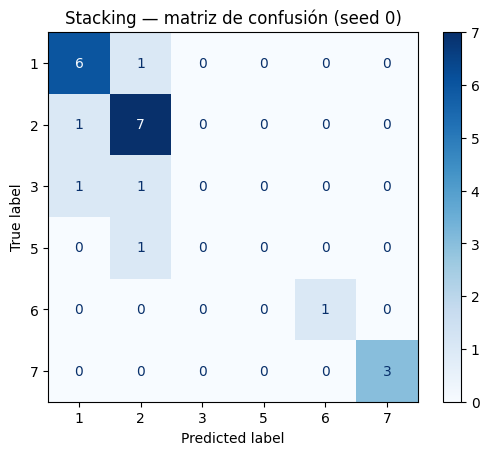

              precision    recall  f1-score   support

           1       0.75      0.86      0.80         7
           2       0.70      0.88      0.78         8
           3       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         1
           6       1.00      1.00      1.00         1
           7       1.00      1.00      1.00         3

    accuracy                           0.77        22
   macro avg       0.58      0.62      0.60        22
weighted avg       0.67      0.77      0.72        22



In [ ]:
X_train, X_test, T_train, T_test = train_test_split(X, T, test_size=0.1, stratify=T, random_state=0)
modelo = crear_stacking(0).fit(X_train, T_train)
ConfusionMatrixDisplay.from_estimator(modelo, X_test, T_test, display_labels=le.classes_, cmap="Blues")
plt.title("Stacking — matriz de confusión (seed 0)"); plt.show()
print(classification_report(T_test, modelo.predict(X_test), target_names=[str(c) for c in le.classes_],
                            zero_division=0))

### Para escribir las conclusiones de la actividad
Algunas preguntas guía:
1. ¿Algún ensamble supera claramente al árbol individual? ¿Los IC se superponen?
2. ¿Qué métrica es más estable (IC más angosto)? ¿Por qué el AUC-ROC suele ser más alto que el F1 macro?
3. ¿Qué pasa con la clase 6 (9 muestras) y la 3 (17 muestras)? Mirá el `classification_report`.
4. ¿El Stacking mejora respecto del mejor de sus modelos base? Si no, ¿qué cambiarías (otro meta-estimador, `passthrough=True`, quitar un base débil)?
5. ¿Vale la pena el costo computacional extra de cada ensamble?

---
## 12. 📌 Resumen / machete

| | **Bagging / Random Forest** | **AdaBoost** | **Gradient Boosting / XGB / LGBM** | **Stacking** |
|---|---|---|---|---|
| Entrenamiento | Paralelo | Secuencial | Secuencial | Base en paralelo + meta |
| Diversidad por | Muestras bootstrap (+ atributos aleatorios en RF) | Reponderar muestras mal clasificadas | Ajustar residuos (gradiente) | Modelos de distinta naturaleza |
| Combinación | Votación (promedio de prob.) | Votación ponderada por $\alpha$ | Suma: $F_0 + \sum \eta\,\gamma$ | Meta-estimador entrenado |
| Reduce | Varianza | Sesgo | Sesgo (y varianza con `subsample`) | Ambos |
| Estimador base típico | Árbol profundo | Stump (`max_depth=1`) | Árbol de 3–8 niveles | Cualquiera, distintos |
| ¿Sobreajusta con más modelos? | No | Sí (puede) | **Sí** → `learning_rate`, early stopping | Riesgo si no se usa `cv` |
| Hiperparámetros clave | `n_estimators`, `max_features` | `n_estimators`, `learning_rate` | `n_estimators`, `learning_rate`, `max_depth`, `subsample` | `estimators`, `final_estimator`, `cv`, `passthrough` |
| Sensible a ruido/outliers | Poco | **Mucho** | Bastante | Depende de los base |

### Errores típicos
* Usar un **árbol completo** como base de AdaBoost (se detiene en 1 modelo).
* No **escalar** los datos para KNN / SVM / Regresión Logística en un stacking.
* Olvidar `average=` y `multi_class=` en métricas **multiclase**.
* Olvidar `stratify=` con clases desbalanceadas y test chico.
* Confundir `test_size`: `test_size=0.1` es **10 % test / 90 % train**.
* Comparar modelos con **una sola partición** (el resultado depende mucho del azar del split).

### ✅ Autoevaluación (hacé clic para ver la respuesta)

<details><summary><b>1.</b> ¿Por qué un Random Forest con 2000 árboles no sobreajusta más que uno con 500, pero un Gradient Boosting con 2000 árboles sí puede?</summary>
En RF cada árbol es independiente y se promedia: agregar árboles sólo estabiliza el promedio. En GB cada árbol corrige errores residuales del anterior: si se agregan demasiados, empieza a ajustar el ruido del train.
</details>

<details><summary><b>2.</b> ¿Qué porcentaje de filas distintas ve en promedio cada árbol con bootstrapping? ¿Para qué sirven las restantes?</summary>
≈ 63,2 %. El ≈ 36,8 % restante (out-of-bag) sirve para estimar el error sin un conjunto de test (<code>oob_score=True</code>).
</details>

<details><summary><b>3.</b> En AdaBoost, ¿qué valor toma α si un modelo débil tiene error 0,5 en un problema binario? ¿Y qué significa?</summary>
α = ln(0,5/0,5) = 0. El modelo es igual al azar y no aporta al voto.
</details>

<details><summary><b>4.</b> En Gradient Boosting binario, ¿por qué el residuo inicial de una muestra de clase 0 es −0,625 en el ejemplo de clase?</summary>
Porque la predicción inicial es p₀ = 5/8 = 0,625 para todos, y residuo = T − p = 0 − 0,625.
</details>

<details><summary><b>5.</b> ¿Por qué StackingClassifier usa validación cruzada para construir el dataset del meta-estimador?</summary>
Para que las predicciones de los modelos base sean sobre datos que no vieron (out-of-fold). Si no, serían demasiado optimistas y el meta-modelo aprendería a confiar en el que más memorizó.
</details>

<details><summary><b>6.</b> ¿Qué cambia con <code>passthrough=True</code>?</summary>
El meta-estimador recibe, además de las predicciones de los modelos base, los atributos originales.
</details>

<details><summary><b>7.</b> Bagging vs. Boosting: ¿cuál reduce varianza y cuál sesgo? ¿Cuál se puede paralelizar?</summary>
Bagging reduce varianza y se paraleliza. Boosting reduce sesgo y es secuencial.
</details>

<details><summary><b>8.</b> ¿Qué diferencia hay entre Random Forest y un BaggingClassifier de árboles con <code>max_features=0.5</code>?</summary>
En Bagging el subconjunto de atributos se sortea una vez por árbol (random subspace). En Random Forest se sortea en cada nodo, lo que descorrelaciona más los árboles.
</details>

---
**Referencias:** documentación de scikit-learn (*Ensembles: Gradient boosting, random forests, bagging, voting, stacking*), documentación de XGBoost y LightGBM, y las diapositivas de la cátedra.